# Comparaison des modèles

On compare ici trois algorithmes, avec exactement la même méthode que pour les modèles de référence : validation croisée stratifiée à 5 plis sur l'entraînement, prétraitement ajusté dans chaque pli, **jeu de test toujours intact**.

- **Régression logistique** : le modèle de référence de l'étape précédente.
- **Forêt aléatoire** : un grand nombre d'arbres de décision entraînés sur des échantillons différents, dont on moyenne les votes.
- **Gradient boosting** : des arbres construits l'un après l'autre, chacun corrigeant les erreurs des précédents.

La règle de sélection est fixée avant de regarder les résultats : **le modèle retenu est celui qui a le meilleur F1 macro sur les cinq familles**. Si deux modèles sont à moins de 0,01 d'écart, on les départage avec le rappel sur U2R et R2L, les deux familles difficiles.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from intrusion_detector.data import CATEGORIES, PROJECT_ROOT, load_train, split_features_target
from intrusion_detector.evaluate import (
    cross_val_predictions,
    cross_validate_binary,
    family_summary,
    per_class_report,
    plot_confusion_matrix,
)
from intrusion_detector.models import candidate_models

sns.set_theme(style="whitegrid", context="notebook")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Nombre de calculs menés en parallèle : monte-le si ton ordinateur a beaucoup de mémoire,
# baisse-le à 1 s'il ralentit trop pendant l'exécution
N_JOBS = 2

train = load_train()
X, y_binary = split_features_target(train, target="is_attack")
_, y_family = split_features_target(train, target="category")

## 1. Détection binaire : normal ou attaque

In [2]:
binary_tables = {
    name: cross_validate_binary(model, X, y_binary, n_jobs=N_JOBS) for name, model in candidate_models().items()
}
binary_summary = pd.DataFrame({name: table["moyenne"] for name, table in binary_tables.items()}).T
binary_summary.sort_values("f1", ascending=False).round(4)

,accuracy,precision,recall,f1,roc_auc
Gradient boosting,0.9990,0.9992,0.9985,0.9989,1.0000
Forêt aléatoire,0.9989,0.9994,0.9981,0.9988,1.0000
Régression logistique,0.9729,0.9776,0.9639,0.9707,0.9964


Les deux méthodes à base d'arbres sont très au-dessus de la régression logistique : un F1 de 0,999 (gradient boosting comme forêt aléatoire) contre 0,971. Le gradient boosting ne rate que 0,15 % des attaques, et 0,07 % de ses alertes sont de fausses alertes. L'écart entre les deux méthodes à base d'arbres est de 0,0001 : la détection binaire ne permet pas de les départager.

Ces scores presque parfaits viennent de la validation croisée sur l'entraînement, où chaque pli contient les mêmes types d'attaques que l'apprentissage. Ils ne disent rien du comportement face aux attaques nouvelles du jeu de test : l'écart attendu est grand.

## 2. Cinq familles, avec et sans pondération des classes

Les familles rares (R2L et U2R) pèsent très peu dans l'apprentissage : se tromper sur 52 connexions U2R coûte presque rien au modèle face à 67 000 connexions normales. La **pondération des classes** corrige cela : chaque erreur sur une famille rare compte davantage. On teste chaque algorithme avec et sans cette pondération.

In [3]:
family_models = {**candidate_models(), **candidate_models(balanced=True)}
family_predictions = {
    name: cross_val_predictions(model, X, y_family, n_jobs=N_JOBS) for name, model in family_models.items()
}

summary = family_summary(family_predictions).sort_values("F1 macro", ascending=False)
summary.round(3)

,normal,dos,probe,r2l,u2r,F1 macro
Forêt aléatoire (poids équilibrés),0.999,1.000,0.998,0.970,0.692,0.941
Gradient boosting (poids équilibrés),0.998,1.000,0.997,0.985,0.788,0.921
Forêt aléatoire,1.000,1.000,0.996,0.961,0.500,0.918
Régression logistique,0.991,0.998,0.959,0.782,0.346,0.839
Gradient boosting,0.996,0.998,0.991,0.915,0.269,0.798
Régression logistique (poids équilibrés),0.942,0.998,0.985,0.959,0.731,0.697


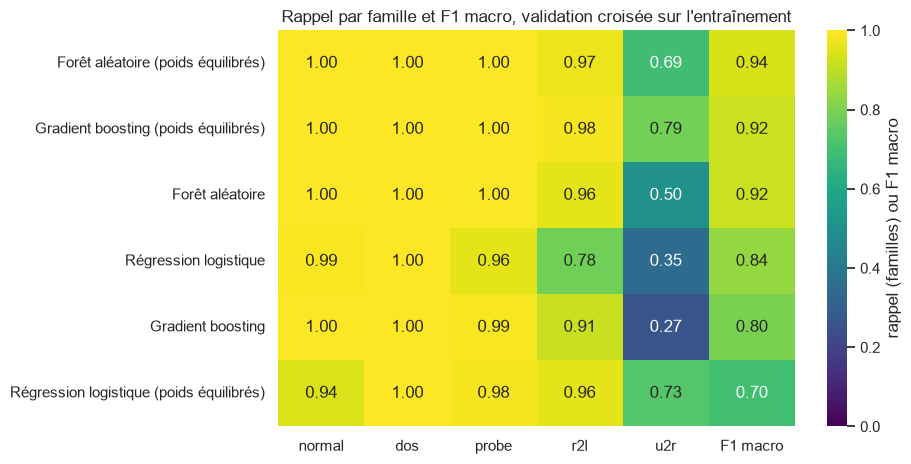

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(
    summary,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "rappel (familles) ou F1 macro"},
    ax=ax,
)
ax.set_title("Rappel par famille et F1 macro, validation croisée sur l'entraînement")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=150)
plt.show()

**La pondération des classes n'aide pas partout.**

- **Gradient boosting** : elle est décisive. Le F1 macro passe de 0,799 à 0,919, le rappel sur U2R de 0,365 à 0,769 et celui sur R2L de 0,923 à 0,983.
- **Forêt aléatoire** : elle est légèrement défavorable. Le F1 macro passe de 0,918 à 0,905 et le rappel sur U2R de 0,500 à 0,423.
- **Régression logistique** : elle est nettement défavorable (F1 macro de 0,845 à 0,698). Le rappel sur U2R monte de 0,385 à 0,731, mais celui sur le trafic normal tombe de 0,991 à 0,942 : près de 6 % des connexions normales sont alors classées comme des attaques.

La pondération se teste, elle ne se suppose pas.

**Selon la règle fixée au départ, le gradient boosting avec poids équilibrés est retenu.** Son F1 macro (0,919) n'est qu'à 0,001 de celui de la forêt aléatoire sans pondération (0,918), donc à moins de 0,01 : on départage avec U2R et R2L, où il fait nettement mieux (0,769 contre 0,500 sur U2R, 0,983 contre 0,961 sur R2L).

**Une réserve sur U2R.** Avec 52 exemples, une seule connexion en plus ou en moins déplace le rappel de presque 2 points. Les écarts entre modèles sur cette famille sont moins fiables que sur les familles nombreuses.

## 3. Zoom sur le meilleur modèle

In [5]:
best_name = summary["F1 macro"].idxmax()
print("Meilleur F1 macro :", best_name)
per_class_report(*family_predictions[best_name]).round(3)

Meilleur F1 macro : Forêt aléatoire (poids équilibrés)


,precision,recall,f1,support
normal,0.999,0.999,0.999,67343
dos,1.000,1.000,1.000,45927
probe,0.998,0.998,0.998,11656
r2l,0.976,0.970,0.973,995
u2r,0.783,0.692,0.735,52
macro avg,0.951,0.932,0.941,125973


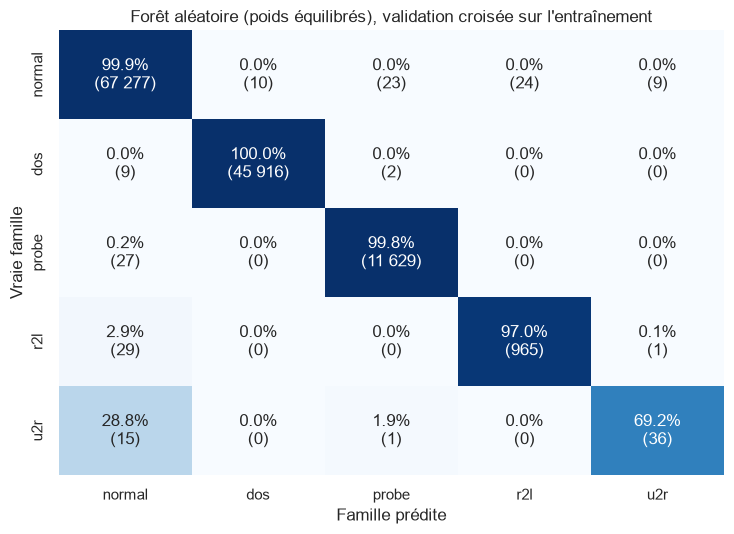

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
plot_confusion_matrix(
    *family_predictions[best_name],
    title=f"{best_name}, validation croisée sur l'entraînement",
    ax=ax,
)
fig.tight_layout()
plt.show()

Le modèle retenu détecte 98,3 % des attaques R2L (978 sur 995) et 76,9 % des attaques U2R (40 sur 52). Ce résultat a un prix : pour attraper ces U2R, il en signale 73 au total, dont 33 fausses alertes (27 viennent de trafic normal), soit une précision de 0,548 sur cette famille. C'est le compromis habituel entre rappel et précision, et il est assumé : dans un outil de détection, rater une attaque coûte plus cher qu'une fausse alerte. Les 9 connexions U2R prises pour du trafic normal restent les erreurs les plus coûteuses.

## 4. Ce qu'on en retient

- Les modèles à base d'arbres surpassent nettement la régression logistique : en binaire, un F1 de 0,999 contre 0,971 ; sur cinq familles, jusqu'à 0,919 de F1 macro contre 0,845.
- Le déséquilibre des classes est le vrai sujet : la pondération fait gagner 12 points de F1 macro au gradient boosting, mais en fait perdre près de 15 à la régression logistique.
- **Modèle retenu pour la suite : le gradient boosting avec poids équilibrés.**
- Aucun modèle n'a été réglé finement : les paramètres sont ceux par défaut, sauf le nombre d'arbres de la forêt. Chercher mieux est possible, mais cela augmenterait le risque de s'adapter à ces plis plutôt qu'aux données.
- Tous ces chiffres viennent de la validation croisée sur l'entraînement. L'étape suivante mesure le modèle retenu sur le jeu de test, une seule fois.